In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
DATA_PATH = '../Data/kc_house_data_NaN.csv'

In [2]:
df = pd.read_csv(DATA_PATH)

print(f'Dataset shape: {df.shape}')
display(df.head())

Dataset shape: (21613, 22)


,Unnamed: 0,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,0,7129300520,20141013T000000,221900.0,3.0,1.00,1180,5650,1.0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,1,6414100192,20141209T000000,538000.0,3.0,2.25,2570,7242,2.0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,2,5631500400,20150225T000000,180000.0,2.0,1.00,770,10000,1.0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,3,2487200875,20141209T000000,604000.0,4.0,3.00,1960,5000,1.0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,4,1954400510,20150218T000000,510000.0,3.0,2.00,1680,8080,1.0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [3]:
df.info()

print('\nData types:')
df.dtypes

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     21613 non-null  int64  
 1   id             21613 non-null  int64  
 2   date           21613 non-null  str    
 3   price          21613 non-null  float64
 4   bedrooms       21600 non-null  float64
 5   bathrooms      21603 non-null  float64
 6   sqft_living    21613 non-null  int64  
 7   sqft_lot       21613 non-null  int64  
 8   floors         21613 non-null  float64
 9   waterfront     21613 non-null  int64  
 10  view           21613 non-null  int64  
 11  condition      21613 non-null  int64  
 12  grade          21613 non-null  int64  
 13  sqft_above     21613 non-null  int64  
 14  sqft_basement  21613 non-null  int64  
 15  yr_built       21613 non-null  int64  
 16  yr_renovated   21613 non-null  int64  
 17  zipcode        21613 non-null  int64  
 18  lat            21

Unnamed: 0         int64
id                 int64
date                 str
price            float64
bedrooms         float64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object

In [4]:
print('Number of Nulls : ')
print(df.isna().sum())


Number of Nulls : 
Unnamed: 0        0
id                0
date              0
price             0
bedrooms         13
bathrooms        10
sqft_living       0
sqft_lot          0
floors            0
waterfront        0
view              0
condition         0
grade             0
sqft_above        0
sqft_basement     0
yr_built          0
yr_renovated      0
zipcode           0
lat               0
long              0
sqft_living15     0
sqft_lot15        0
dtype: int64


In [5]:
df['bedrooms'] = df['bedrooms'].fillna(df['bedrooms'].median())
df['bathrooms'] = df['bathrooms'].fillna(df['bathrooms'].median())

In [6]:
print('Number of Uniques : ')
print(df.nunique())

Number of Uniques : 
Unnamed: 0       21613
id               21436
date               372
price             4028
bedrooms            12
bathrooms           29
sqft_living       1038
sqft_lot          9782
floors               6
waterfront           2
view                 5
condition            5
grade               12
sqft_above         946
sqft_basement      306
yr_built           116
yr_renovated        70
zipcode             70
lat               5034
long               752
sqft_living15      777
sqft_lot15        8689
dtype: int64


In [7]:
df.drop(columns=['Unnamed: 0', 'id'],inplace=True)

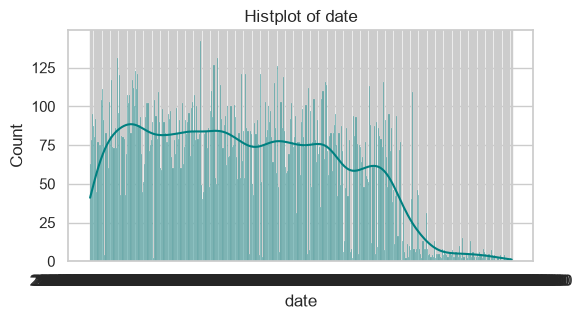

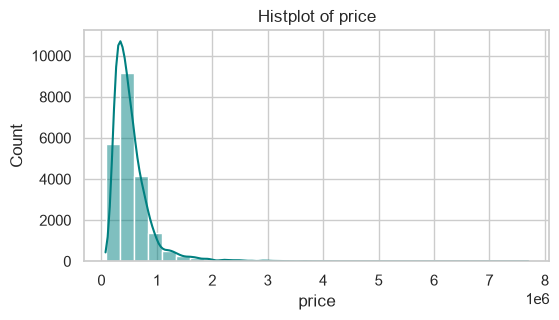

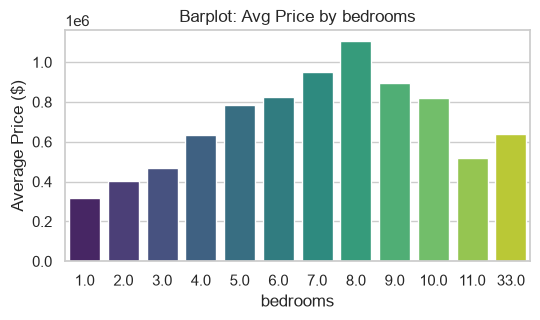

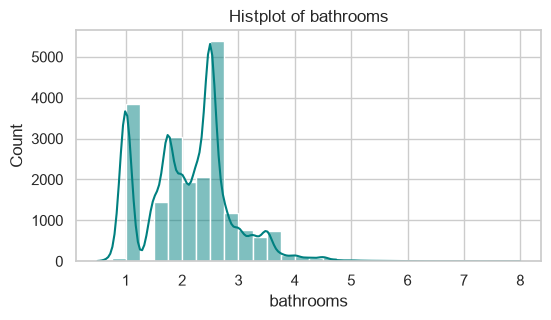

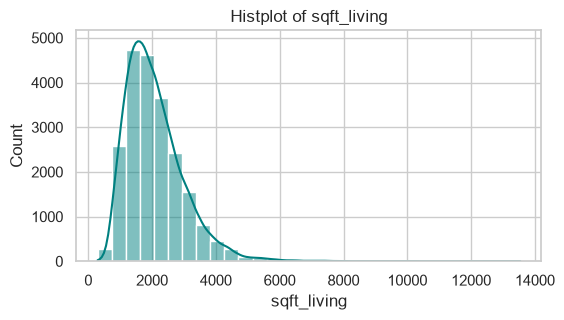

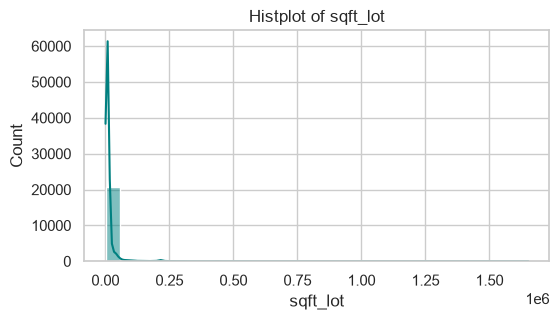

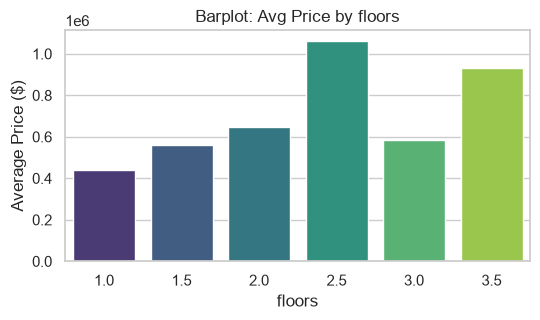

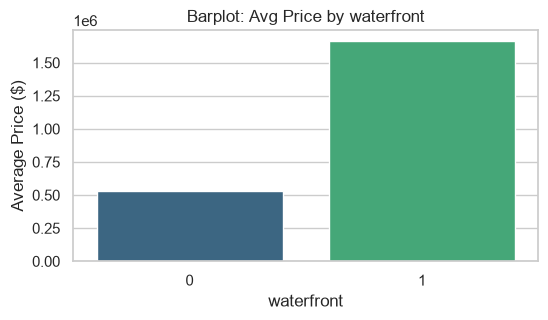

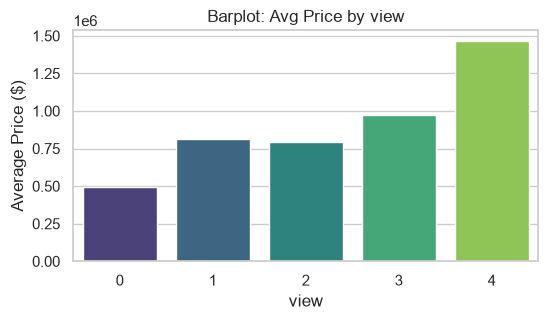

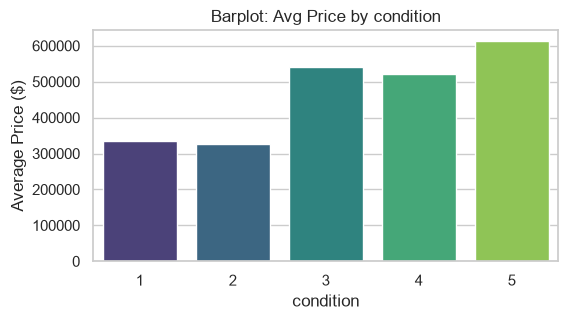

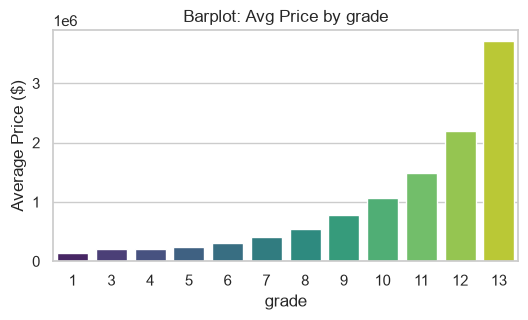

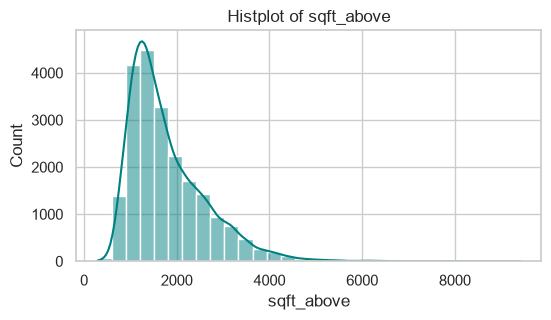

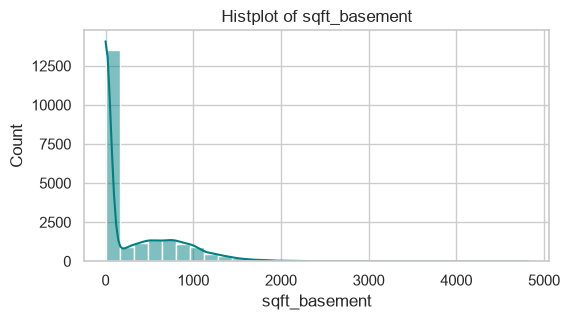

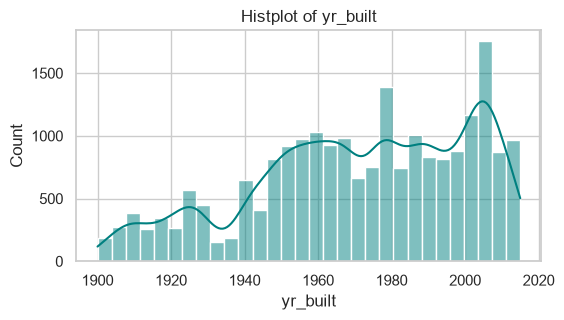

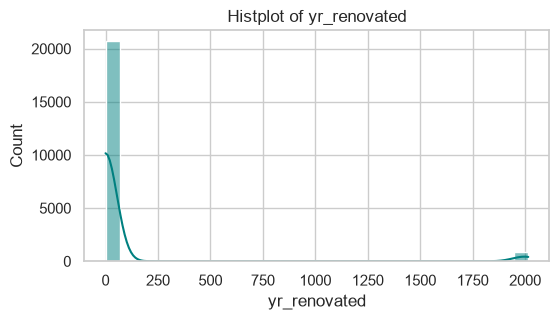

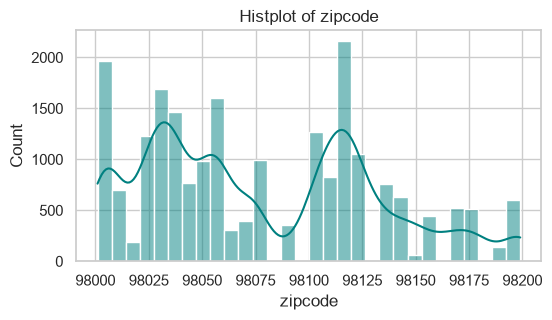

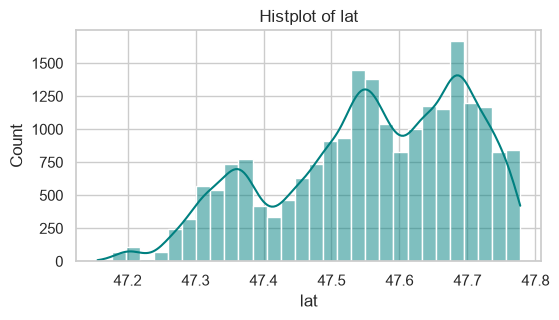

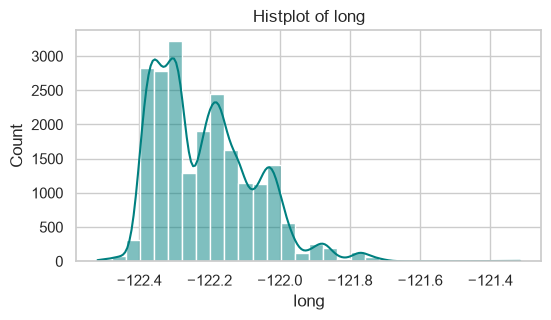

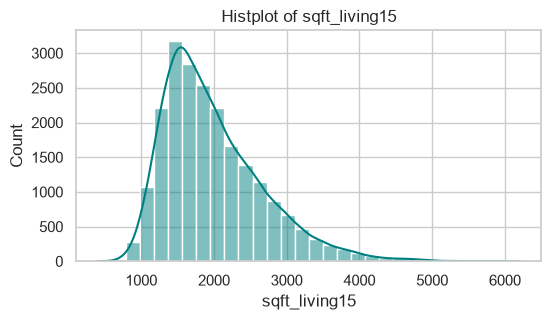

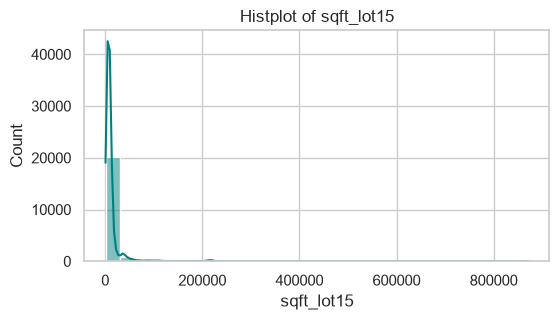

In [8]:
for col in df:
    plt.figure(figsize=(6, 3))
    
    if df[col].nunique() <= 15:
        sns.barplot(data=df, x=col, y='price', palette='viridis', errorbar=None)
        plt.title(f'Barplot: Avg Price by {col}')
        plt.ylabel('Average Price ($)')
    else:
        sns.histplot(df[col], kde=True, color='teal', bins=30)
        plt.title(f'Histplot of {col}')
        plt.ylabel('Count')
        
    plt.show()

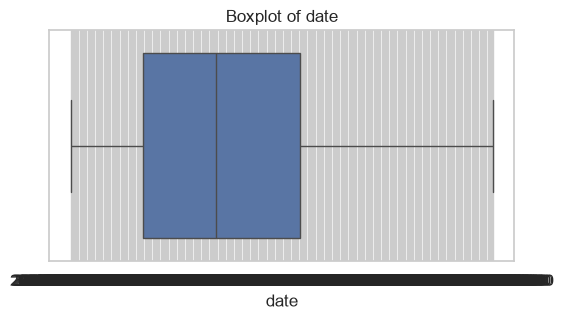

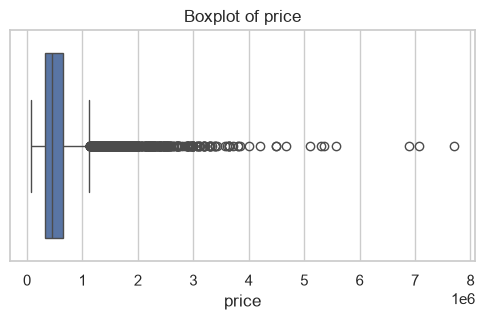

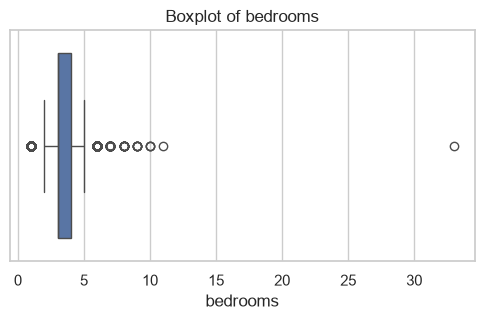

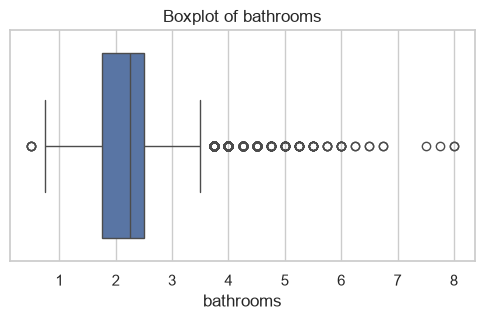

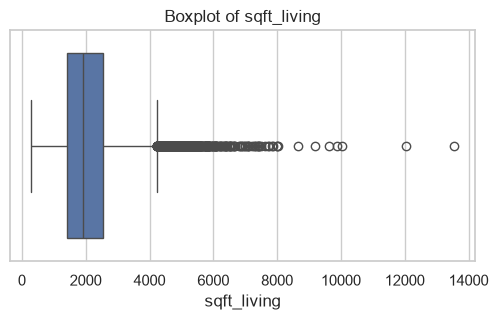

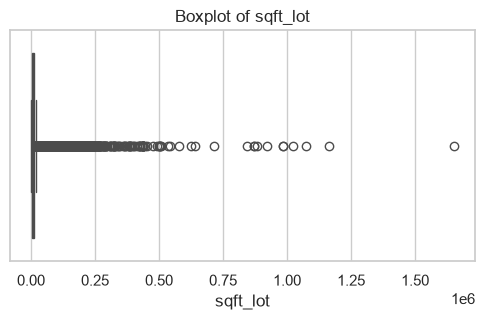

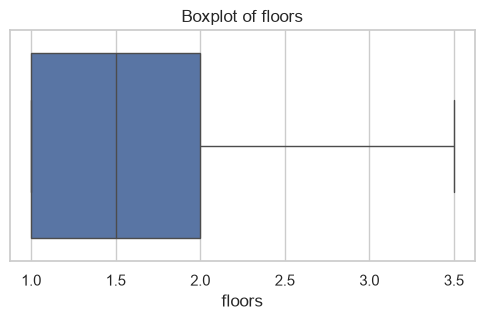

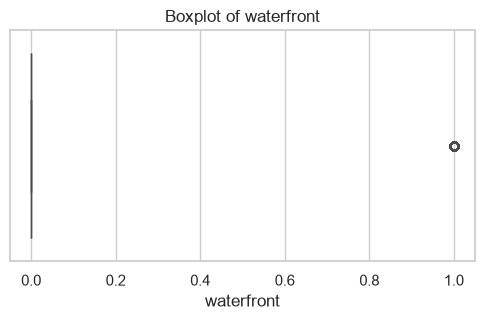

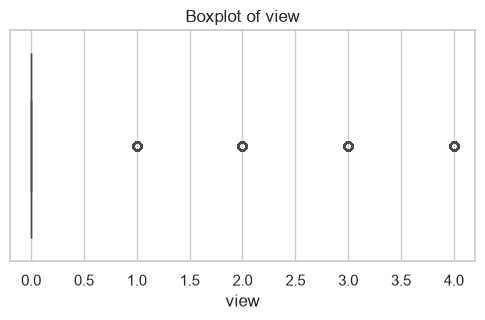

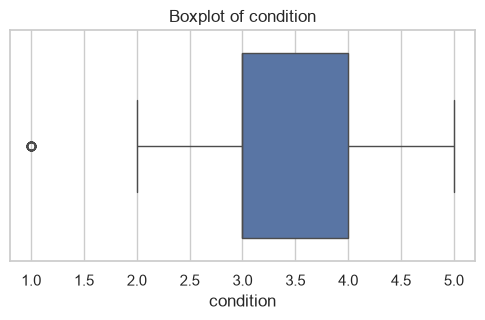

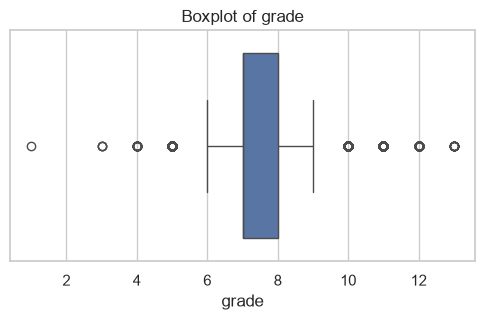

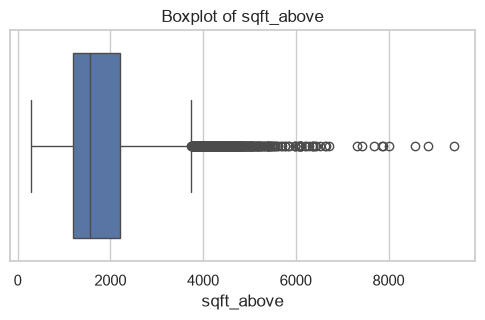

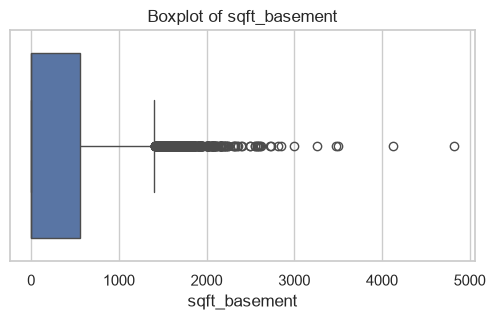

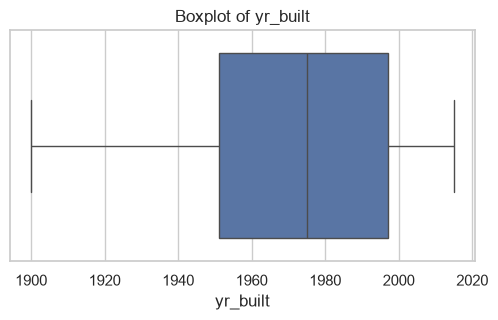

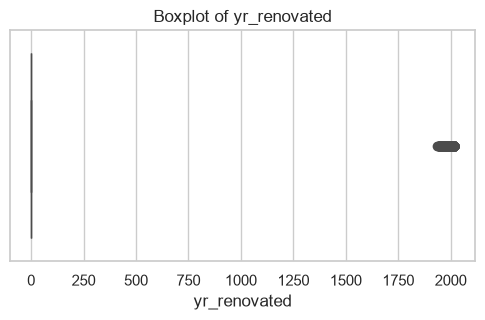

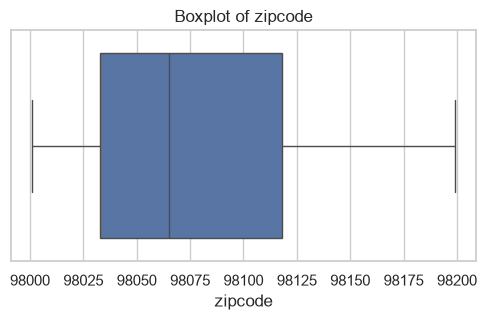

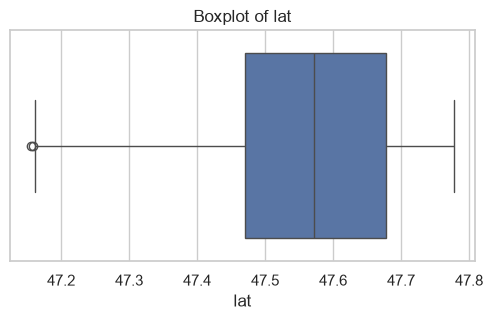

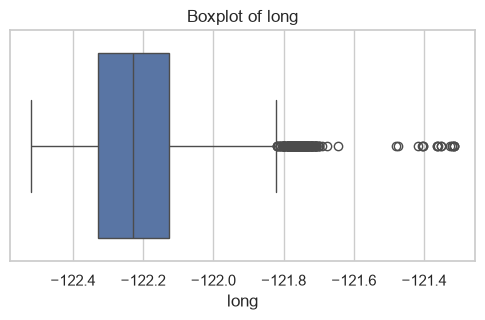

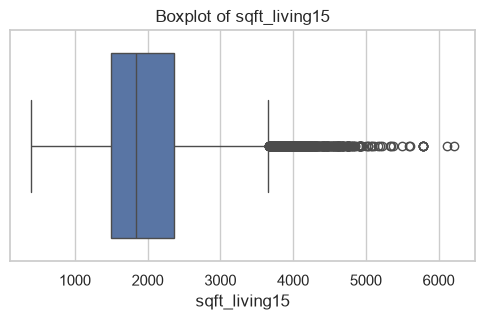

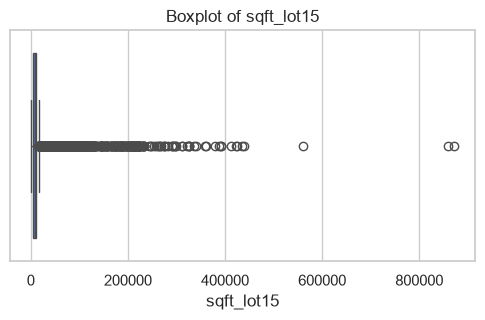

In [9]:
for col in df:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)
    plt.show()

In [10]:
df['date'] = pd.to_datetime(df['date'])

df = df[(df['bedrooms'] > 0) & (df['bedrooms'] <= 15)]

df['has_basement'] = (df['sqft_basement'] > 0).astype(int)

df['log_price'] = np.log1p(df['price'])

df['sale_year'] = df['date'].dt.year
df['sale_month'] = df['date'].dt.month
df['house_age'] = (df['sale_year'] - df['yr_built']).clip(lower=0)

df['is_renovated'] = (df['yr_renovated'] > 0).astype(int)

df['years_since_renovation'] = np.where(
    df['is_renovated'].eq(1),
    (df['sale_year'] - df['yr_renovated']).clip(lower=0),
    df['house_age']
)

df['total_rooms'] = df['bedrooms'] + df['bathrooms']
df['price_per_sqft'] = df['price'] / df['sqft_living'].clip(lower=1)
df['has_basement'] = (df['sqft_basement'] > 0).astype(int)
df['living_to_lot_ratio'] = df['sqft_living'] / df['sqft_lot'].clip(lower=1)
df['basement_to_lot_ration'] = df['sqft_basement'] / df['sqft_lot'].clip(lower=1)

df.drop(columns=['sqft_basement', 'sqft_above', 'yr_built', 'yr_renovated'],inplace=True) # High correlation with sqft Living

df

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,log_price,sale_year,sale_month,house_age,is_renovated,years_since_renovation,total_rooms,price_per_sqft,living_to_lot_ratio,basement_to_lot_ration
0,2014-10-13,221900.0,3.0,1.00,1180,5650,1.0,0,0,3,...,12.309987,2014,10,59,0,59,4.00,188.050847,0.208850,0.000000
1,2014-12-09,538000.0,3.0,2.25,2570,7242,2.0,0,0,3,...,13.195616,2014,12,63,1,23,5.25,209.338521,0.354874,0.055233
2,2015-02-25,180000.0,2.0,1.00,770,10000,1.0,0,0,3,...,12.100718,2015,2,82,0,82,3.00,233.766234,0.077000,0.000000
3,2014-12-09,604000.0,4.0,3.00,1960,5000,1.0,0,0,5,...,13.311331,2014,12,49,0,49,7.00,308.163265,0.392000,0.182000
4,2015-02-18,510000.0,3.0,2.00,1680,8080,1.0,0,0,3,...,13.142168,2015,2,28,0,28,5.00,303.571429,0.207921,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,2014-05-21,360000.0,3.0,2.50,1530,1131,3.0,0,0,3,...,12.793862,2014,5,5,0,5,5.50,235.294118,1.352785,0.000000
21609,2015-02-23,400000.0,4.0,2.50,2310,5813,2.0,0,0,3,...,12.899222,2015,2,1,0,1,6.50,173.160173,0.397385,0.000000
21610,2014-06-23,402101.0,2.0,0.75,1020,1350,2.0,0,0,3,...,12.904461,2014,6,5,0,5,2.75,394.216667,0.755556,0.000000
21611,2015-01-16,400000.0,3.0,2.50,1600,2388,2.0,0,0,3,...,12.899222,2015,1,11,0,11,5.50,250.000000,0.670017,0.000000


In [11]:
corr = df.corr(numeric_only=True)

threshold = 0.3

print("Features that has High corr with price:")
for feature, val in corr['price'].items():
    if feature != 'price' and abs(val) >= threshold:
        print(f"{feature}: {val:.4f}")
print()
print("Features that has Low corr with price:")
for feature, val in corr['price'].items():
    if feature != 'price' and abs(val) <= threshold:
        print(f"{feature}: {val:.4f}")

Features that has High corr with price:
bedrooms: 0.3160
bathrooms: 0.5257
sqft_living: 0.7020
view: 0.3973
grade: 0.6674
lat: 0.3070
sqft_living15: 0.5854
log_price: 0.8917
total_rooms: 0.4714
price_per_sqft: 0.5547

Features that has Low corr with price:
sqft_lot: 0.0897
floors: 0.2568
waterfront: 0.2664
condition: 0.0363
zipcode: -0.0532
long: 0.0216
sqft_lot15: 0.0825
has_basement: 0.1802
sale_year: 0.0036
sale_month: -0.0101
house_age: -0.0540
is_renovated: 0.1261
years_since_renovation: -0.1057
living_to_lot_ratio: 0.1231
basement_to_lot_ration: 0.1736


In [12]:
threshold = 0.6
seen_pairs = set()

print("Highly correlated feature pairs:")
for col1 in corr.columns:
    if col1 == 'price' or col1 == 'log_price': 
        continue
    
    for col2 in corr.columns:
        if col2 == 'price' or col1 == col2 or col2 == 'log_price':
            continue
            
        if (col2, col1) not in seen_pairs:  
            val = corr.loc[col1, col2]
            if abs(val) >= threshold:
                print(f"{col1} <-> {col2}: {val:.4f}")
            seen_pairs.add((col1, col2))

Highly correlated feature pairs:
bedrooms <-> total_rooms: 0.8949
bathrooms <-> sqft_living: 0.7553
bathrooms <-> grade: 0.6646
bathrooms <-> total_rooms: 0.8512
sqft_living <-> grade: 0.7627
sqft_living <-> sqft_living15: 0.7564
sqft_living <-> total_rooms: 0.7632
sqft_lot <-> sqft_lot15: 0.7186
grade <-> sqft_living15: 0.7132
has_basement <-> basement_to_lot_ration: 0.7268
sale_year <-> sale_month: -0.7824
house_age <-> years_since_renovation: 0.9100


In [13]:
df

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,log_price,sale_year,sale_month,house_age,is_renovated,years_since_renovation,total_rooms,price_per_sqft,living_to_lot_ratio,basement_to_lot_ration
0,2014-10-13,221900.0,3.0,1.00,1180,5650,1.0,0,0,3,...,12.309987,2014,10,59,0,59,4.00,188.050847,0.208850,0.000000
1,2014-12-09,538000.0,3.0,2.25,2570,7242,2.0,0,0,3,...,13.195616,2014,12,63,1,23,5.25,209.338521,0.354874,0.055233
2,2015-02-25,180000.0,2.0,1.00,770,10000,1.0,0,0,3,...,12.100718,2015,2,82,0,82,3.00,233.766234,0.077000,0.000000
3,2014-12-09,604000.0,4.0,3.00,1960,5000,1.0,0,0,5,...,13.311331,2014,12,49,0,49,7.00,308.163265,0.392000,0.182000
4,2015-02-18,510000.0,3.0,2.00,1680,8080,1.0,0,0,3,...,13.142168,2015,2,28,0,28,5.00,303.571429,0.207921,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,2014-05-21,360000.0,3.0,2.50,1530,1131,3.0,0,0,3,...,12.793862,2014,5,5,0,5,5.50,235.294118,1.352785,0.000000
21609,2015-02-23,400000.0,4.0,2.50,2310,5813,2.0,0,0,3,...,12.899222,2015,2,1,0,1,6.50,173.160173,0.397385,0.000000
21610,2014-06-23,402101.0,2.0,0.75,1020,1350,2.0,0,0,3,...,12.904461,2014,6,5,0,5,2.75,394.216667,0.755556,0.000000
21611,2015-01-16,400000.0,3.0,2.50,1600,2388,2.0,0,0,3,...,12.899222,2015,1,11,0,11,5.50,250.000000,0.670017,0.000000


In [14]:
df.to_csv('../Data/CleanedData.csv')